# Netflix Content Portfolio Intelligence
## Data Audit, Cleaning, Preparation & Exploratory Analysis

Complete workflow built so far for the project.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
sns.set_context("notebook")


In [2]:
RAW_PATH = "../data/raw/Dataset.csv"
df = pd.read_csv(RAW_PATH)
print("Dataset loaded successfully.")
display(df.head())


Dataset loaded successfully.


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [3]:
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())
print("\nData types:")
print(df.dtypes)


Dataset shape: (8790, 10)

Columns:
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']

Data types:
show_id           str
type              str
title             str
director          str
country           str
date_added        str
release_year    int64
rating            str
duration          str
listed_in         str
dtype: object


In [4]:
print("Technical missing values:")
print(df.isnull().sum())
print("\n'Not Given' values:")
for col in df.columns:
    count = (df[col].astype(str).str.strip() == "Not Given").sum()
    if count > 0:
        print(f"{col}: {count}")


Technical missing values:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

'Not Given' values:
director: 2588
country: 287


In [5]:
print("Exact duplicate rows:", df.duplicated().sum())
duplicate_subset = ["type","title","director","country","date_added","release_year","rating","duration","listed_in"]
duplicate_content = df.duplicated(subset=duplicate_subset, keep=False)
print("Potential business duplicate rows:", duplicate_content.sum())
display(df.loc[duplicate_content].sort_values("title"))


Exact duplicate rows: 0
Potential business duplicate rows: 6


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
2925,s3963,Movie,15-Aug,Swapnaneel Jayakar,India,3/29/2019,2019,TV-14,124 min,"Comedies, Dramas, Independent Movies"
4261,s5967,Movie,15-Aug,Swapnaneel Jayakar,India,3/29/2019,2019,TV-14,124 min,"Comedies, Dramas, Independent Movies"
3285,s4523,Movie,22-Jul,Paul Greengrass,Norway,10/10/2018,2018,R,144 min,"Dramas, Thrillers"
4260,s5966,Movie,22-Jul,Paul Greengrass,Norway,10/10/2018,2018,R,144 min,"Dramas, Thrillers"
393,s3997,TV Show,9-Feb,Not Given,Pakistan,3/20/2019,2018,TV-14,1 Season,"International TV Shows, TV Dramas"
537,s5965,TV Show,9-Feb,Not Given,Pakistan,3/20/2019,2018,TV-14,1 Season,"International TV Shows, TV Dramas"


In [6]:
df_clean = df.drop_duplicates(subset=duplicate_subset, keep="first").copy()
print("Original rows:", len(df))
print("Cleaned rows:", len(df_clean))
print("Removed business duplicates:", len(df) - len(df_clean))


Original rows: 8790
Cleaned rows: 8787
Removed business duplicates: 3


In [7]:
df_clean["date_added"] = pd.to_datetime(df_clean["date_added"], errors="coerce")
print("Invalid dates after conversion:", df_clean["date_added"].isna().sum())
df_clean["year_added"] = df_clean["date_added"].dt.year
df_clean["month_added"] = df_clean["date_added"].dt.month_name()
display(df_clean[["date_added","year_added","month_added"]].head())


Invalid dates after conversion: 0


,date_added,year_added,month_added
0,2021-09-25,2021,September
1,2021-09-24,2021,September
2,2021-09-24,2021,September
3,2021-09-22,2021,September
4,2021-09-24,2021,September


In [8]:
df_clean["duration_value"] = df_clean["duration"].str.extract(r"(\d+)").astype(int)
df_clean["duration_unit"] = df_clean["duration"].str.extract(r"([A-Za-z]+)")[0]
print(df_clean["duration_unit"].value_counts())
display(df_clean[["type","duration","duration_value","duration_unit"]].head(10))


duration_unit
min        6124
Season     1790
Seasons     873
Name: count, dtype: int64


,type,duration,duration_value,duration_unit
0,Movie,90 min,90,min
1,TV Show,1 Season,1,Season
2,TV Show,1 Season,1,Season
3,Movie,91 min,91,min
4,Movie,125 min,125,min
5,TV Show,9 Seasons,9,Seasons
6,Movie,104 min,104,min
7,Movie,87 min,87,min
8,Movie,127 min,127,min
9,Movie,76 min,76,min


In [9]:
df_clean["duration_unit"] = df_clean["duration_unit"].replace({"Season":"seasons","Seasons":"seasons","min":"minutes"})
print(df_clean["duration_unit"].value_counts())


duration_unit
minutes    6124
seasons    2663
Name: count, dtype: int64


In [10]:
df_clean["content_age_at_addition"] = df_clean["year_added"] - df_clean["release_year"]
negative_age_mask = df_clean["content_age_at_addition"] < 0
print("Negative content age records:", negative_age_mask.sum())
display(df_clean.loc[negative_age_mask,["title","type","release_year","year_added","content_age_at_addition"]].sort_values("content_age_at_addition"))


Negative content age records: 14


,title,type,release_year,year_added,content_age_at_addition
5178,Jack Taylor,TV Show,2016,2013,-3
8223,Sense8,TV Show,2018,2016,-2
5138,Incoming,Movie,2019,2018,-1
3869,Hans Teeuwen: Real Rancour,Movie,2018,2017,-1
6992,Polly Pocket,TV Show,2021,2020,-1
7355,Love Is Blind,TV Show,2021,2020,-1
7436,Fuller House,TV Show,2020,2019,-1
6948,Hilda,TV Show,2021,2020,-1
7484,Maradona in Mexico,TV Show,2020,2019,-1
7517,BoJack Horseman,TV Show,2020,2019,-1


In [11]:
df_clean["content_age_valid"] = df_clean["content_age_at_addition"].where(df_clean["content_age_at_addition"] >= 0)
print("Valid content age records:", df_clean["content_age_valid"].notna().sum())
print("Excluded negative records:", df_clean["content_age_valid"].isna().sum())


Valid content age records: 8773
Excluded negative records: 14


In [12]:
df_clean["director_clean"] = df_clean["director"].replace("Not Given","Unknown")
df_clean["country_clean"] = df_clean["country"].replace("Not Given","Unknown")
print("Unknown directors:", (df_clean["director_clean"] == "Unknown").sum())
print("Unknown countries:", (df_clean["country_clean"] == "Unknown").sum())


Unknown directors: 2587
Unknown countries: 287


In [13]:
genres = (df_clean[["show_id","type","title","listed_in"]]
          .assign(genre=df_clean["listed_in"].str.split(","))
          .explode("genre"))
genres["genre"] = genres["genre"].str.strip()
print("Original content records:", len(df_clean))
print("Exploded genre rows:", len(genres))
print("Unique genres:", genres["genre"].nunique())
display(genres.head(10))


Original content records: 8787
Exploded genre rows: 19287
Unique genres: 42


,show_id,type,title,listed_in,genre
0,s1,Movie,Dick Johnson Is Dead,Documentaries,Documentaries
1,s3,TV Show,Ganglands,"Crime TV Shows, International TV Shows, TV Act...",Crime TV Shows
1,s3,TV Show,Ganglands,"Crime TV Shows, International TV Shows, TV Act...",International TV Shows
1,s3,TV Show,Ganglands,"Crime TV Shows, International TV Shows, TV Act...",TV Action & Adventure
2,s6,TV Show,Midnight Mass,"TV Dramas, TV Horror, TV Mysteries",TV Dramas
2,s6,TV Show,Midnight Mass,"TV Dramas, TV Horror, TV Mysteries",TV Horror
2,s6,TV Show,Midnight Mass,"TV Dramas, TV Horror, TV Mysteries",TV Mysteries
3,s14,Movie,Confessions of an Invisible Girl,"Children & Family Movies, Comedies",Children & Family Movies
3,s14,Movie,Confessions of an Invisible Girl,"Children & Family Movies, Comedies",Comedies
4,s8,Movie,Sankofa,"Dramas, Independent Movies, International Movies",Dramas


In [14]:
genre_counts = genres["genre"].value_counts()
print(genre_counts.to_string())


genre
International Movies            2752
Dramas                          2424
Comedies                        1673
International TV Shows          1348
Documentaries                    869
Action & Adventure               859
TV Dramas                        761
Independent Movies               755
Children & Family Movies         641
Romantic Movies                  616
Thrillers                        576
TV Comedies                      573
Crime TV Shows                   469
Kids' TV                         448
Docuseries                       394
Music & Musicals                 375
Romantic TV Shows                370
Horror Movies                    357
Stand-Up Comedy                  343
Reality TV                       255
British TV Shows                 252
Sci-Fi & Fantasy                 243
Sports Movies                    219
Anime Series                     174
Spanish-Language TV Shows        173
TV Action & Adventure            167
Korean TV Shows                 

In [15]:
sorted(genres["genre"].unique())


['Action & Adventure',
 'Anime Features',
 'Anime Series',
 'British TV Shows',
 'Children & Family Movies',
 'Classic & Cult TV',
 'Classic Movies',
 'Comedies',
 'Crime TV Shows',
 'Cult Movies',
 'Documentaries',
 'Docuseries',
 'Dramas',
 'Faith & Spirituality',
 'Horror Movies',
 'Independent Movies',
 'International Movies',
 'International TV Shows',
 "Kids' TV",
 'Korean TV Shows',
 'LGBTQ Movies',
 'Movies',
 'Music & Musicals',
 'Reality TV',
 'Romantic Movies',
 'Romantic TV Shows',
 'Sci-Fi & Fantasy',
 'Science & Nature TV',
 'Spanish-Language TV Shows',
 'Sports Movies',
 'Stand-Up Comedy',
 'Stand-Up Comedy & Talk Shows',
 'TV Action & Adventure',
 'TV Comedies',
 'TV Dramas',
 'TV Horror',
 'TV Mysteries',
 'TV Sci-Fi & Fantasy',
 'TV Shows',
 'TV Thrillers',
 'Teen TV Shows',
 'Thrillers']

In [16]:
rating_groups = {
    "TV-Y":"Kids","TV-Y7":"Kids","TV-Y7-FV":"Kids","G":"Kids",
    "TV-G":"Family","PG":"Family",
    "TV-PG":"Teens & Family","PG-13":"Teens & Family",
    "TV-14":"Teens",
    "TV-MA":"Mature","R":"Mature","NC-17":"Mature",
    "NR":"Unrated","UR":"Unrated"
}
df_clean["audience_group"] = df_clean["rating"].map(rating_groups)
print(df_clean["audience_group"].value_counts(dropna=False))


audience_group
Mature            4006
Teens             2155
Teens & Family    1351
Kids               686
Family             507
Unrated             82
Name: count, dtype: int64


In [17]:
age_bins = [-1,0,2,5,10,float("inf")]
age_labels = ["Same Year","1-2 Years","3-5 Years","6-10 Years","10+ Years"]
df_clean["content_age_group"] = pd.cut(df_clean["content_age_valid"], bins=age_bins, labels=age_labels)
content_age_groups = df_clean["content_age_group"].value_counts().reindex(age_labels)
display(content_age_groups)


content_age_group
Same Year     3237
1-2 Years     2296
3-5 Years     1117
6-10 Years     918
10+ Years     1205
Name: count, dtype: int64

In [18]:
print("Final cleaned shape:", df_clean.shape)
print("\nDuplicate show_id:")
print(df_clean["show_id"].duplicated().sum())
print("\nTechnical missing values:")
print(df_clean.isnull().sum())
print("\nContent types:")
print(df_clean["type"].value_counts())
print("\nRelease year range:")
print(df_clean["release_year"].min(), "to", df_clean["release_year"].max())
print("\nDate added range:")
print(df_clean["date_added"].min(), "to", df_clean["date_added"].max())


Final cleaned shape: (8787, 20)

Duplicate show_id:
0

Technical missing values:
show_id                     0
type                        0
title                       0
director                    0
country                     0
date_added                  0
release_year                0
rating                      0
duration                    0
listed_in                   0
year_added                  0
month_added                 0
duration_value              0
duration_unit               0
content_age_at_addition     0
content_age_valid          14
director_clean              0
country_clean               0
audience_group              0
content_age_group          14
dtype: int64

Content types:
type
Movie      6124
TV Show    2663
Name: count, dtype: int64

Release year range:
1925 to 2021

Date added range:
2008-01-01 00:00:00 to 2021-09-25 00:00:00


In [19]:
PROCESSED_DIR = "../data/processed"
os.makedirs(PROCESSED_DIR, exist_ok=True)
clean_output_path = os.path.join(PROCESSED_DIR,"netflix_cleaned.csv")
genre_output_path = os.path.join(PROCESSED_DIR,"netflix_genres.csv")
df_clean.to_csv(clean_output_path, index=False)
genres.to_csv(genre_output_path, index=False)
print("Clean dataset saved:", os.path.exists(clean_output_path))
print("Genre dataset saved:", os.path.exists(genre_output_path))


Clean dataset saved: True
Genre dataset saved: True


## Executive Overview KPIs


In [20]:
total_titles = len(df_clean)
total_movies = (df_clean["type"] == "Movie").sum()
total_tv_shows = (df_clean["type"] == "TV Show").sum()
total_countries = df_clean.loc[df_clean["country_clean"] != "Unknown","country_clean"].nunique()
total_genres = genres["genre"].nunique()
kpi_summary = {
    "Total Titles": total_titles,
    "Movies": total_movies,
    "TV Shows": total_tv_shows,
    "Countries": total_countries,
    "Genres": total_genres,
    "Avg Movie Duration": round(df_clean.loc[df_clean["type"] == "Movie","duration_value"].mean(),1),
    "Avg TV Seasons": round(df_clean.loc[df_clean["type"] == "TV Show","duration_value"].mean(),2)
}
kpi_summary


{'Total Titles': 8787,
 'Movies': np.int64(6124),
 'TV Shows': np.int64(2663),
 'Countries': 85,
 'Genres': 42,
 'Avg Movie Duration': np.float64(99.6),
 'Avg TV Seasons': np.float64(1.75)}

## Content Type Analysis


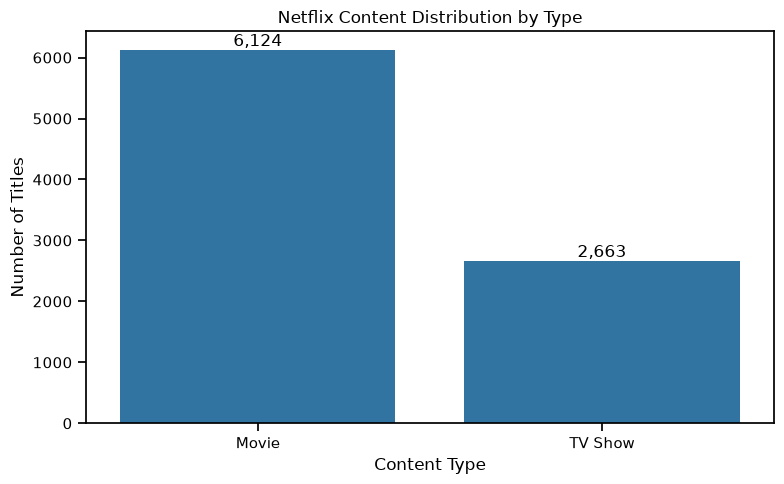

In [21]:
content_counts = df_clean["type"].value_counts()
plt.figure(figsize=(8,5))
sns.barplot(x=content_counts.index, y=content_counts.values)
plt.title("Netflix Content Distribution by Type")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
for i,value in enumerate(content_counts.values):
    plt.text(i,value,f"{value:,}",ha="center",va="bottom")
plt.tight_layout()
plt.show()


In [22]:
content_distribution = df_clean["type"].value_counts().to_frame("count")
content_distribution["percentage"] = (content_distribution["count"] / content_distribution["count"].sum() * 100).round(2)
display(content_distribution)


,count,percentage
type,,
Movie,6124,69.69
TV Show,2663,30.31


## Country Analysis


In [23]:
top_countries = df_clean[df_clean["country_clean"] != "Unknown"]["country_clean"].value_counts().head(10)
display(top_countries)


country_clean
United States     3240
India             1056
United Kingdom     638
Pakistan           420
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Mexico             138
Name: count, dtype: int64

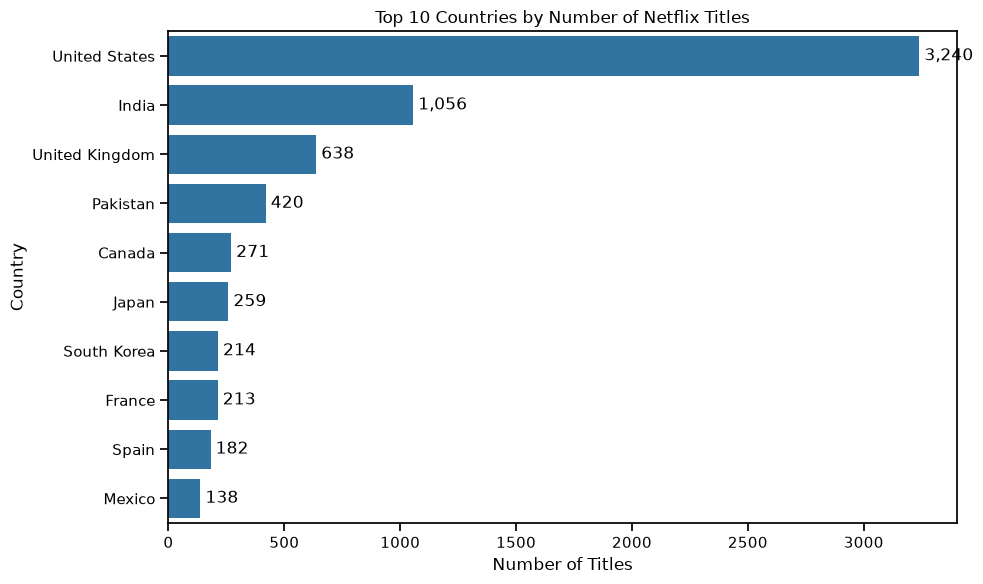

In [24]:
plt.figure(figsize=(10,6))
sns.barplot(x=top_countries.values, y=top_countries.index)
plt.title("Top 10 Countries by Number of Netflix Titles")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
for i,value in enumerate(top_countries.values):
    plt.text(value,i,f" {value:,}",va="center")
plt.tight_layout()
plt.show()


In [25]:
top_country_names = top_countries.index
country_type = (df_clean[(df_clean["country_clean"].isin(top_country_names)) & (df_clean["country_clean"] != "Unknown")]
                .groupby(["country_clean","type"]).size().unstack(fill_value=0))
display(country_type)


type,Movie,TV Show
country_clean,,
Canada,187,84
France,148,65
India,975,81
Japan,87,172
Mexico,90,48
Pakistan,71,349
South Korea,49,165
Spain,129,53
United Kingdom,387,251


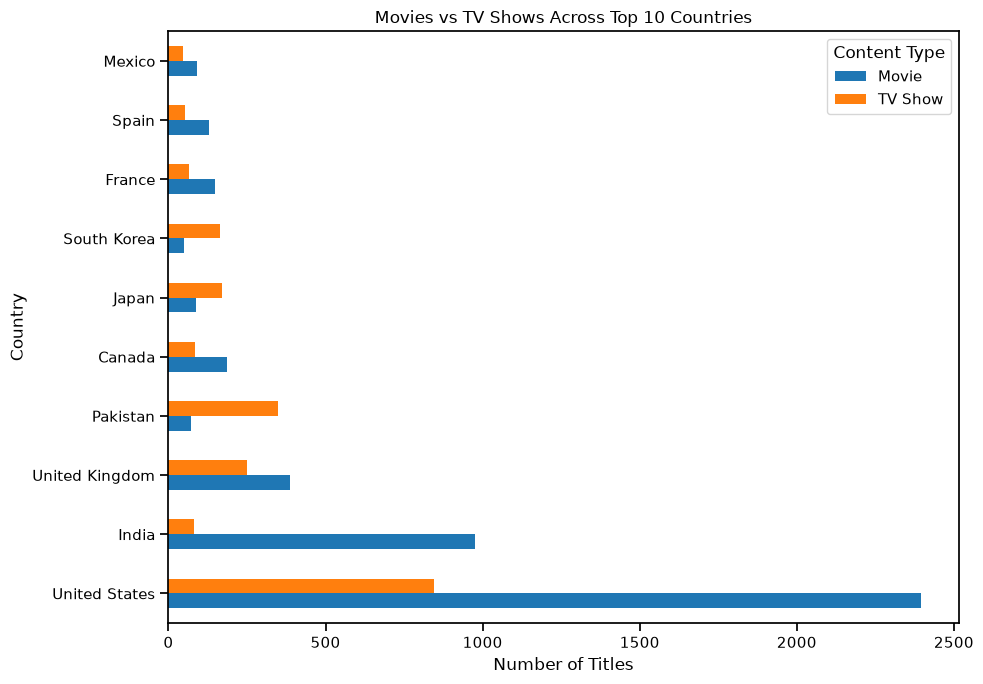

In [26]:
country_type_plot = country_type.loc[top_country_names]
country_type_plot.plot(kind="barh", figsize=(10,7))
plt.title("Movies vs TV Shows Across Top 10 Countries")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.legend(title="Content Type")
plt.tight_layout()
plt.show()


In [27]:
country_type_pct = country_type.div(country_type.sum(axis=1), axis=0).mul(100).round(2)
display(country_type_pct)


type,Movie,TV Show
country_clean,,
Canada,69.00,31.00
France,69.48,30.52
India,92.33,7.67
Japan,33.59,66.41
Mexico,65.22,34.78
Pakistan,16.90,83.10
South Korea,22.90,77.10
Spain,70.88,29.12
United Kingdom,60.66,39.34


## Trend Analysis


In [28]:
release_trend = df_clean.groupby("release_year").size()
display(release_trend.tail(20))


release_year
2002      51
2003      59
2004      64
2005      80
2006      96
2007      88
2008     135
2009     152
2010     192
2011     185
2012     236
2013     286
2014     352
2015     555
2016     901
2017    1030
2018    1144
2019    1029
2020     953
2021     592
dtype: int64

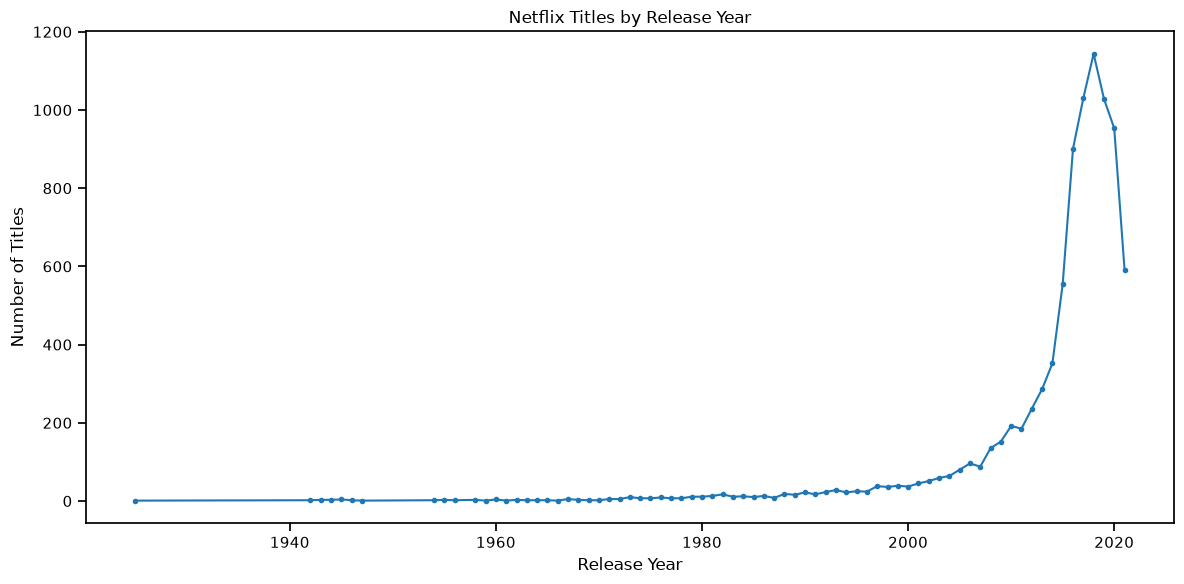

In [29]:
plt.figure(figsize=(12,6))
plt.plot(release_trend.index, release_trend.values, marker="o", markersize=3)
plt.title("Netflix Titles by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()


In [30]:
release_type_trend = df_clean.groupby(["release_year","type"]).size().unstack(fill_value=0)
display(release_type_trend.tail(20))


type,Movie,TV Show
release_year,,
2002,44,7
2003,51,8
2004,55,9
2005,67,13
2006,82,14
2007,74,14
2008,113,22
2009,118,34
2010,153,39


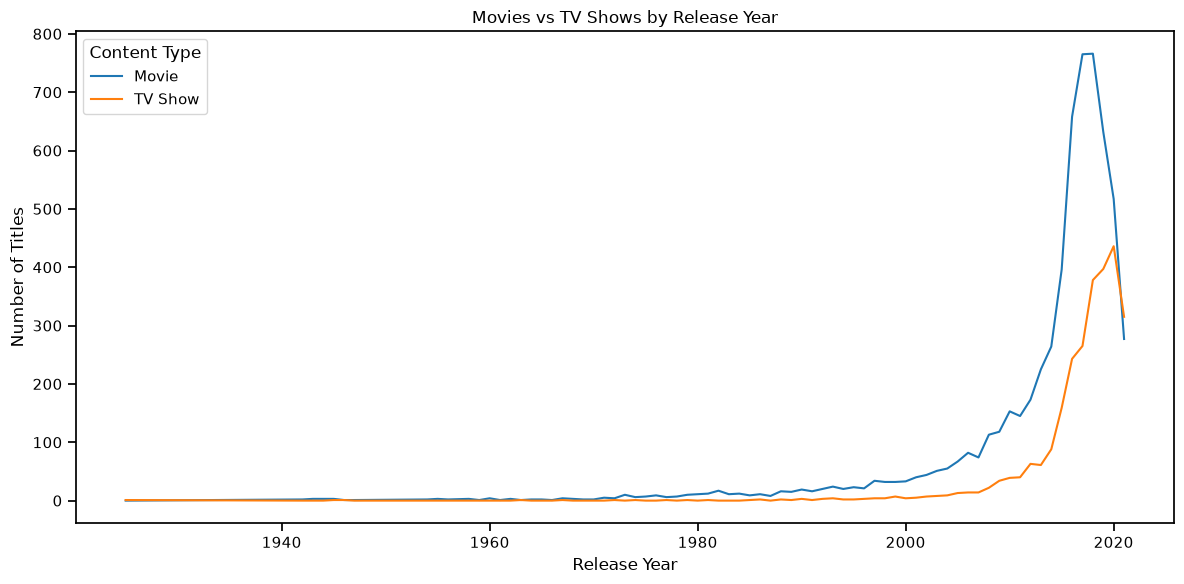

In [31]:
release_type_trend.plot(figsize=(12,6))
plt.title("Movies vs TV Shows by Release Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.legend(title="Content Type")
plt.tight_layout()
plt.show()


In [32]:
added_trend = df_clean.groupby("year_added").size()
display(added_trend)


year_added
2008       2
2009       2
2010       1
2011      13
2012       3
2013      11
2014      24
2015      82
2016     426
2017    1185
2018    1647
2019    2014
2020    1879
2021    1498
dtype: int64

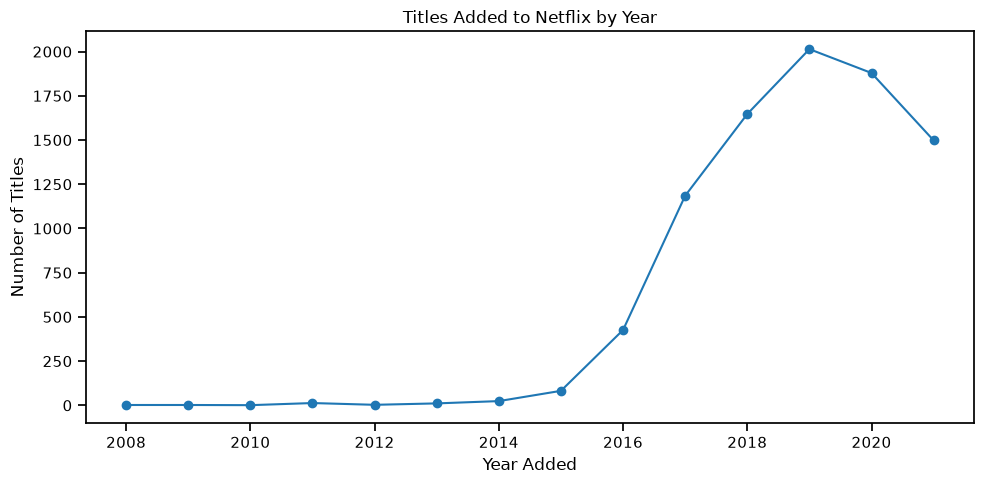

In [33]:
plt.figure(figsize=(10,5))
plt.plot(added_trend.index, added_trend.values, marker="o")
plt.title("Titles Added to Netflix by Year")
plt.xlabel("Year Added")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()


In [34]:
added_type_trend = df_clean.groupby(["year_added","type"]).size().unstack(fill_value=0)
display(added_type_trend)


type,Movie,TV Show
year_added,,
2008,1,1
2009,2,0
2010,1,0
2011,13,0
2012,3,0
2013,6,5
2014,19,5
2015,56,26
2016,251,175


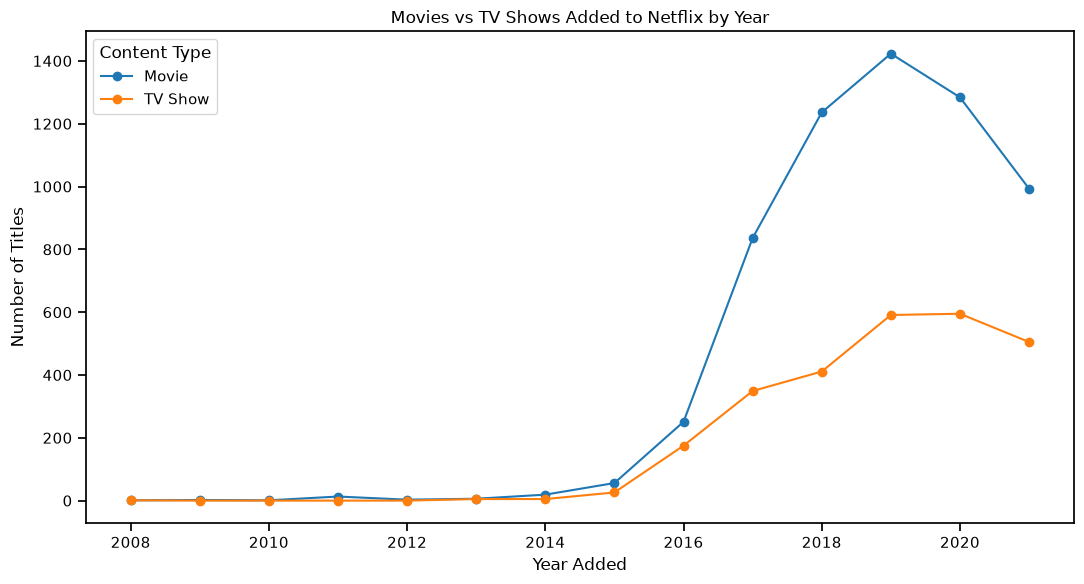

In [35]:
added_type_trend.plot(figsize=(11,6), marker="o")
plt.title("Movies vs TV Shows Added to Netflix by Year")
plt.xlabel("Year Added")
plt.ylabel("Number of Titles")
plt.legend(title="Content Type")
plt.tight_layout()
plt.show()


## Rating & Audience Analysis


In [36]:
rating_counts = df_clean["rating"].value_counts()
display(rating_counts)


rating
TV-MA       3205
TV-14       2155
TV-PG        861
R            798
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64

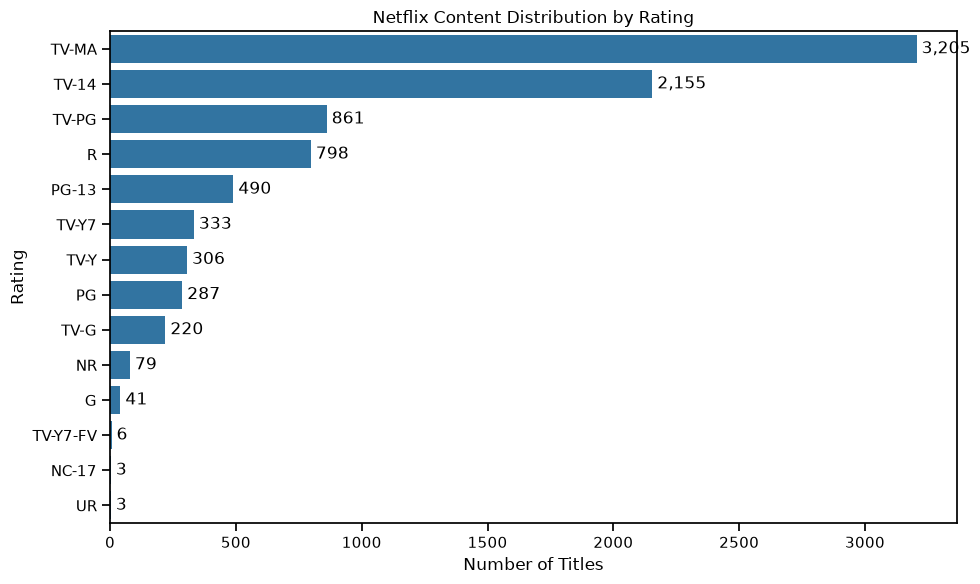

In [37]:
plt.figure(figsize=(10,6))
sns.barplot(x=rating_counts.values, y=rating_counts.index)
plt.title("Netflix Content Distribution by Rating")
plt.xlabel("Number of Titles")
plt.ylabel("Rating")
for i,value in enumerate(rating_counts.values):
    plt.text(value,i,f" {value:,}",va="center")
plt.tight_layout()
plt.show()


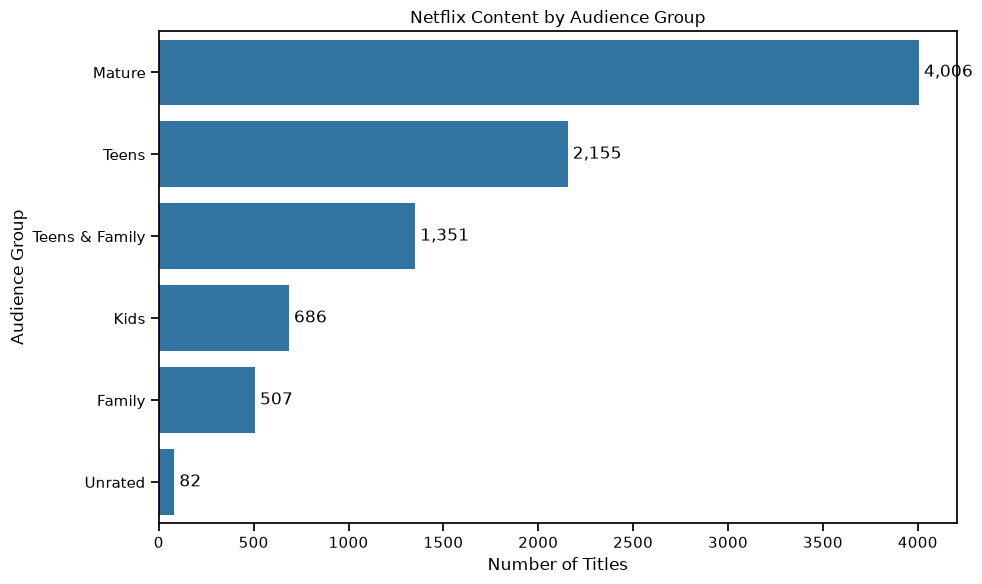

In [38]:
audience_counts = df_clean["audience_group"].value_counts()
plt.figure(figsize=(10,6))
sns.barplot(x=audience_counts.values, y=audience_counts.index)
plt.title("Netflix Content by Audience Group")
plt.xlabel("Number of Titles")
plt.ylabel("Audience Group")
for i,value in enumerate(audience_counts.values):
    plt.text(value,i,f" {value:,}",va="center")
plt.tight_layout()
plt.show()


In [39]:
audience_type = df_clean.groupby(["audience_group","type"]).size().unstack(fill_value=0)
display(audience_type)


type,Movie,TV Show
audience_group,,
Family,413,94
Kids,316,370
Mature,2861,1145
Teens,1426,729
Teens & Family,1030,321
Unrated,78,4


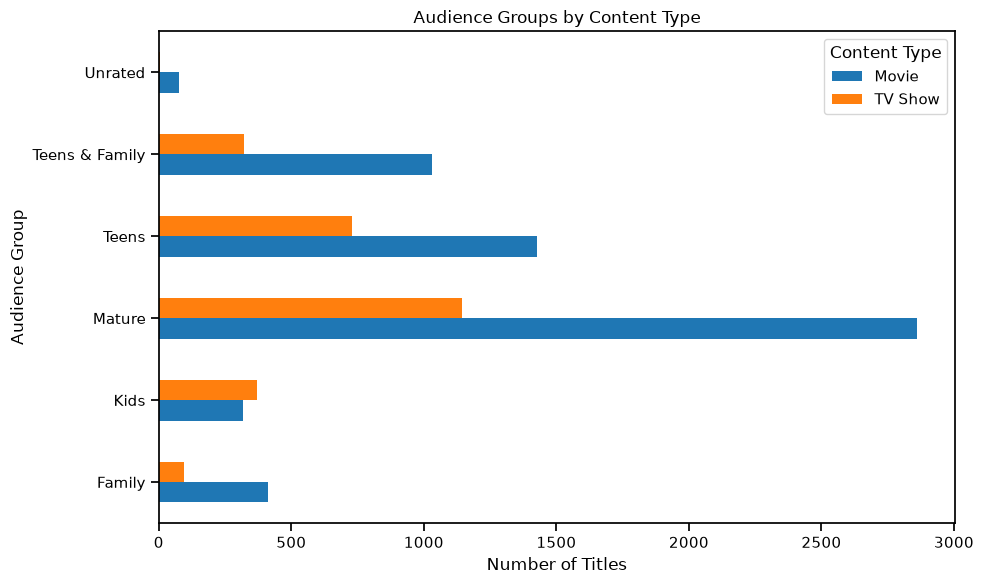

In [40]:
audience_type.plot(kind="barh", figsize=(10,6))
plt.title("Audience Groups by Content Type")
plt.xlabel("Number of Titles")
plt.ylabel("Audience Group")
plt.legend(title="Content Type")
plt.tight_layout()
plt.show()


## Genre Analysis


In [41]:
top_genres = genres["genre"].value_counts().head(15)
display(top_genres)


genre
International Movies        2752
Dramas                      2424
Comedies                    1673
International TV Shows      1348
Documentaries                869
Action & Adventure           859
TV Dramas                    761
Independent Movies           755
Children & Family Movies     641
Romantic Movies              616
Thrillers                    576
TV Comedies                  573
Crime TV Shows               469
Kids' TV                     448
Docuseries                   394
Name: count, dtype: int64

In [42]:
movie_genres = genres[genres["type"] == "Movie"]["genre"].value_counts().head(10)
tv_genres = genres[genres["type"] == "TV Show"]["genre"].value_counts().head(10)
print("Top Movie Genres:")
print(movie_genres)
print("\nTop TV Show Genres:")
print(tv_genres)


Top Movie Genres:
genre
International Movies        2752
Dramas                      2424
Comedies                    1673
Documentaries                869
Action & Adventure           859
Independent Movies           755
Children & Family Movies     641
Romantic Movies              616
Thrillers                    576
Music & Musicals             375
Name: count, dtype: int64

Top TV Show Genres:
genre
International TV Shows    1348
TV Dramas                  761
TV Comedies                573
Crime TV Shows             469
Kids' TV                   448
Docuseries                 394
Romantic TV Shows          370
Reality TV                 255
British TV Shows           252
Anime Series               174
Name: count, dtype: int64


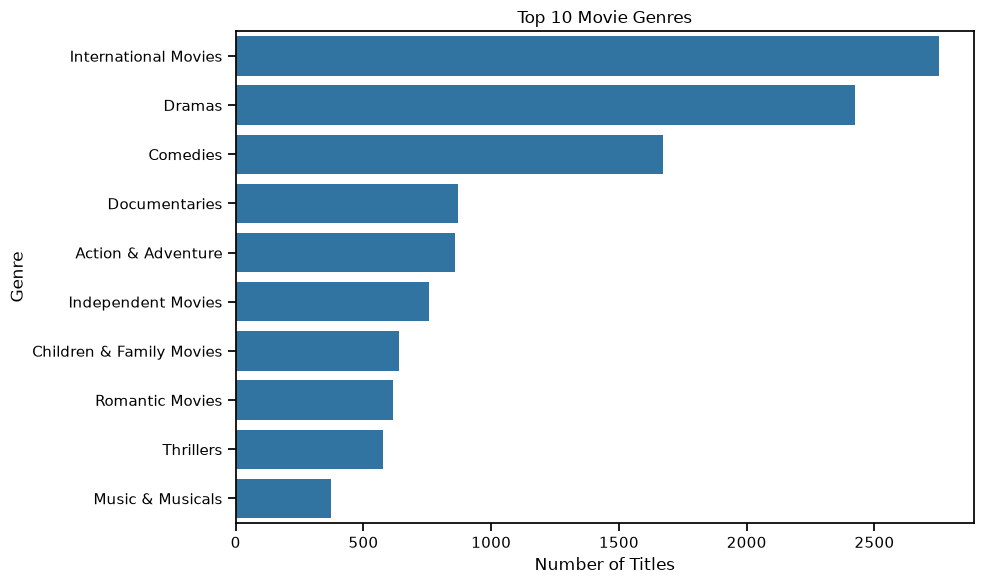

In [43]:
plt.figure(figsize=(10,6))
sns.barplot(x=movie_genres.values, y=movie_genres.index)
plt.title("Top 10 Movie Genres")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()


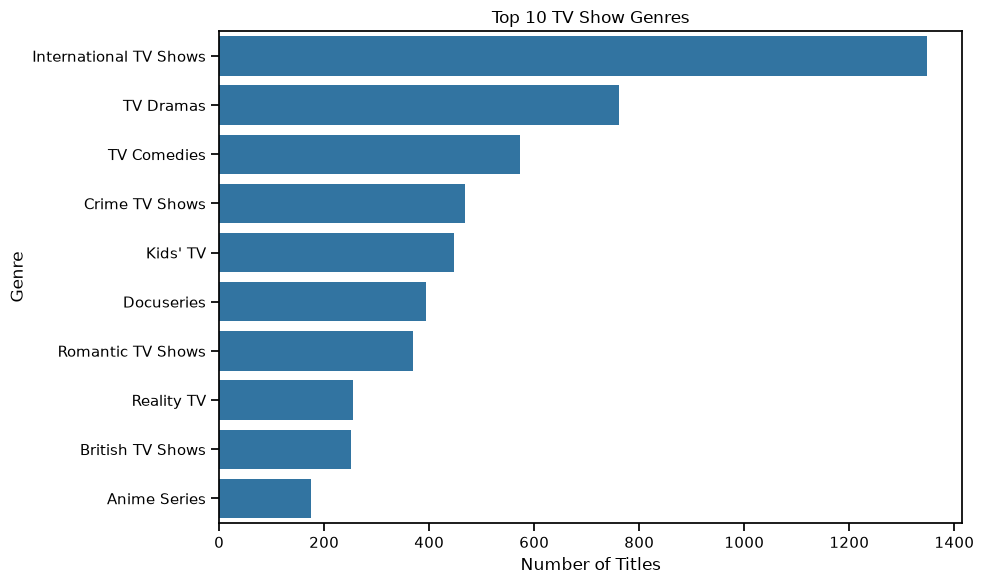

In [44]:
plt.figure(figsize=(10,6))
sns.barplot(x=tv_genres.values, y=tv_genres.index)
plt.title("Top 10 TV Show Genres")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()


## Duration Analysis


In [45]:
movie_duration = df_clean.loc[df_clean["type"] == "Movie","duration_value"]
print("Movie duration statistics:")
print(movie_duration.describe())


Movie duration statistics:
count    6124.000000
mean       99.573645
std        28.280425
min         3.000000
25%        87.000000
50%        98.000000
75%       114.000000
max       312.000000
Name: duration_value, dtype: float64


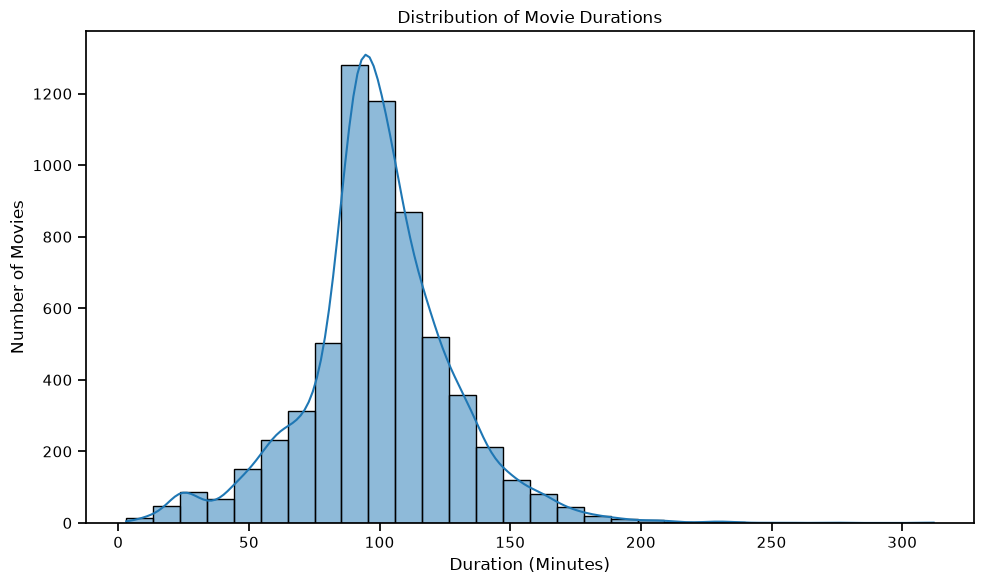

In [46]:
plt.figure(figsize=(10,6))
sns.histplot(movie_duration, bins=30, kde=True)
plt.title("Distribution of Movie Durations")
plt.xlabel("Duration (Minutes)")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()


In [47]:
tv_seasons = df_clean.loc[df_clean["type"] == "TV Show","duration_value"]
print("TV Show season statistics:")
print(tv_seasons.describe())


TV Show season statistics:
count    2663.000000
mean        1.752159
std         1.550844
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        17.000000
Name: duration_value, dtype: float64


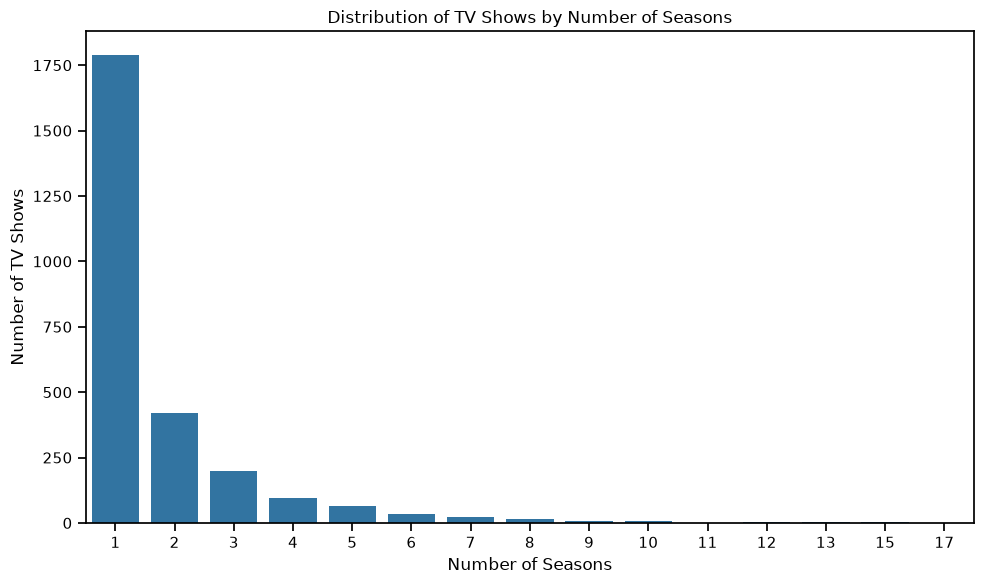

In [48]:
season_counts = tv_seasons.value_counts().sort_index()
plt.figure(figsize=(10,6))
sns.barplot(x=season_counts.index, y=season_counts.values)
plt.title("Distribution of TV Shows by Number of Seasons")
plt.xlabel("Number of Seasons")
plt.ylabel("Number of TV Shows")
plt.tight_layout()
plt.show()


## Content Age Analysis


In [49]:
content_age = df_clean["content_age_valid"].dropna()
print("Content age statistics:")
print(content_age.describe())


Content age statistics:
count    8773.000000
mean        4.701356
std         8.794971
min         0.000000
25%         0.000000
50%         1.000000
75%         5.000000
max        93.000000
Name: content_age_valid, dtype: float64


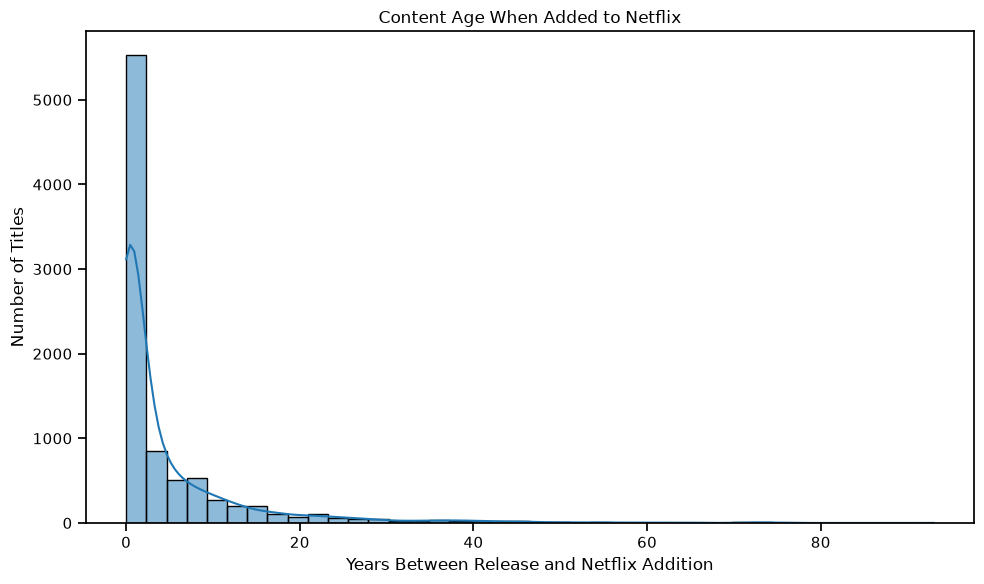

In [50]:
plt.figure(figsize=(10,6))
sns.histplot(content_age, bins=40, kde=True)
plt.title("Content Age When Added to Netflix")
plt.xlabel("Years Between Release and Netflix Addition")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()


In [51]:
content_age_summary = content_age_groups.to_frame("count")
content_age_summary["percentage"] = (content_age_summary["count"] / content_age_summary["count"].sum() * 100).round(2)
display(content_age_summary)


,count,percentage
content_age_group,,
Same Year,3237,36.90
1-2 Years,2296,26.17
3-5 Years,1117,12.73
6-10 Years,918,10.46
10+ Years,1205,13.74


In [52]:
age_type = df_clean.groupby(["content_age_group","type"], observed=False).size().unstack(fill_value=0)
display(age_type)


type,Movie,TV Show
content_age_group,,
Same Year,1858,1379
1-2 Years,1667,629
3-5 Years,811,306
6-10 Years,711,207
10+ Years,1075,130


In [53]:
age_type_pct = age_type.div(age_type.sum(axis=0), axis=1).mul(100).round(2)
display(age_type_pct)


type,Movie,TV Show
content_age_group,,
Same Year,30.35,52.02
1-2 Years,27.23,23.73
3-5 Years,13.25,11.54
6-10 Years,11.61,7.81
10+ Years,17.56,4.90


## Country × Audience Analysis


In [54]:
country_audience = (df_clean[(df_clean["country_clean"].isin(top_country_names)) & (df_clean["country_clean"] != "Unknown")]
                    .groupby(["country_clean","audience_group"]).size().unstack(fill_value=0))
display(country_audience)


audience_group,Family,Kids,Mature,Teens,Teens & Family,Unrated
country_clean,,,,,,
Canada,27,43,125,38,34,4
France,11,25,129,33,13,2
India,13,53,268,573,145,4
Japan,6,21,92,93,47,0
Mexico,2,4,103,14,11,4
Pakistan,16,89,139,113,63,0
South Korea,2,17,92,84,16,3
Spain,4,5,148,17,7,1
United Kingdom,40,36,322,86,144,10


In [55]:
country_audience_pct = country_audience.div(country_audience.sum(axis=1), axis=0).mul(100).round(2)
display(country_audience_pct)


audience_group,Family,Kids,Mature,Teens,Teens & Family,Unrated
country_clean,,,,,,
Canada,9.96,15.87,46.13,14.02,12.55,1.48
France,5.16,11.74,60.56,15.49,6.10,0.94
India,1.23,5.02,25.38,54.26,13.73,0.38
Japan,2.32,8.11,35.52,35.91,18.15,0.00
Mexico,1.45,2.90,74.64,10.14,7.97,2.90
Pakistan,3.81,21.19,33.10,26.90,15.00,0.00
South Korea,0.93,7.94,42.99,39.25,7.48,1.40
Spain,2.20,2.75,81.32,9.34,3.85,0.55
United Kingdom,6.27,5.64,50.47,13.48,22.57,1.57


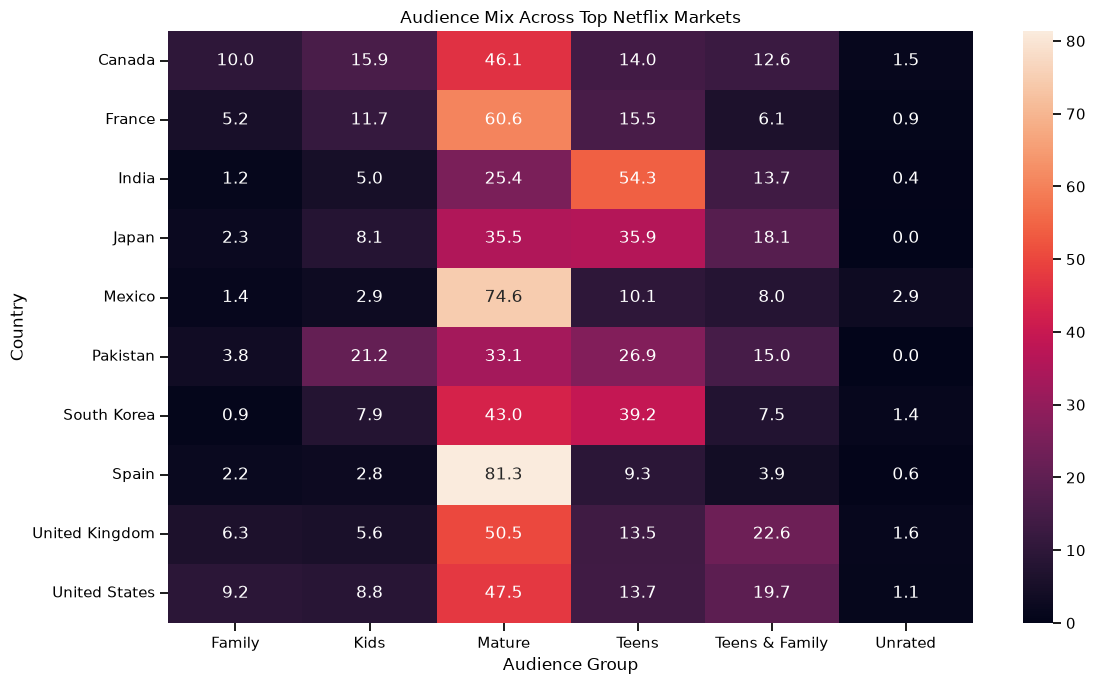

In [56]:
plt.figure(figsize=(12,7))
sns.heatmap(country_audience_pct, annot=True, fmt=".1f")
plt.title("Audience Mix Across Top Netflix Markets")
plt.xlabel("Audience Group")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


## Key Findings So Far

- Cleaned dataset contains 8,787 unique content records after removing 3 business duplicates.
- The source contains no technical nulls, but it includes semantic missing values represented as `Not Given`.
- Movies make up the majority of the catalog.
- The United States is the largest represented market by title count.
- Market content mix varies significantly between Movies and TV Shows.
- Mature and teen-oriented content dominate the catalog.
- About 63% of titles were added within two years of release.
- TV Shows tend to be added closer to release than Movies.
- Genre patterns differ substantially between Movies and TV Shows.
